# 01 — Exploratory data analysis

Explores the processed splits produced by `scripts/build_dataset.py`.
Only aggregate statistics are shown: individual messages are never printed, even though PII has already been masked.

Reproduce: `python scripts/download_data.py && python scripts/build_dataset.py`, then run all cells.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from smishguard import config
from smishguard.data.normalize import ascii_fold, normalize_for_matching

splits = {name: pd.read_csv(config.PROCESSED_DIR / f"{name}.csv") for name in config.SPLIT_NAMES}
df = pd.concat([part.assign(split=name) for name, part in splits.items()], ignore_index=True)
df["label_name"] = df["label"].map({0: "legitimate", 1: "malicious"})
df.shape

(806, 6)

## Class distribution per split and source

In [2]:
pd.crosstab([df["split"], df["source"]], df["label_name"], margins=True)

label_name        legitimate  malicious  All
split source                                
test  turkishsms          61         51  112
train synthetic           20         42   62
      turkishsms         283        237  520
val   turkishsms          61         51  112
All                      425        381  806

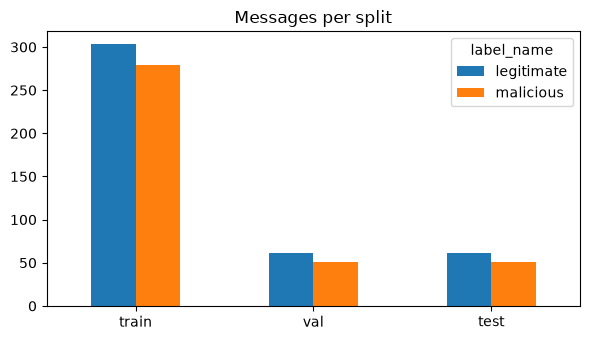

In [3]:
ax = (
    pd.crosstab(df["split"], df["label_name"])
    .loc[list(config.SPLIT_NAMES)]
    .plot.bar(rot=0, figsize=(6, 3.5), title="Messages per split")
)
ax.set_xlabel("")
plt.tight_layout()

## Message length (characters)

In [4]:
df["length"] = df["text"].str.len()
df.groupby("label_name")["length"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
legitimate,425.0,55.1,41.3,4.0,23.0,43.0,77.0,241.0
malicious,381.0,144.2,27.8,43.0,130.0,153.0,159.0,270.0


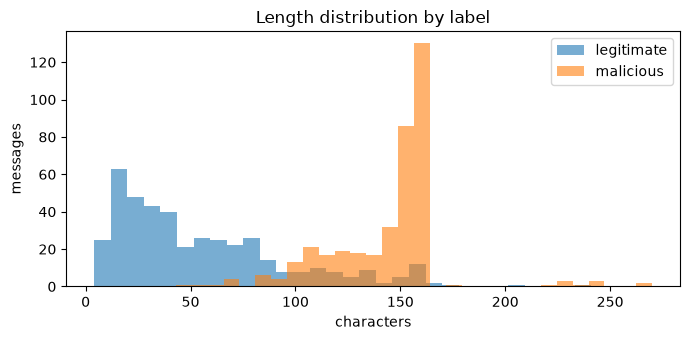

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, part in df.groupby("label_name"):
    ax.hist(part["length"], bins=30, alpha=0.6, label=name)
ax.set_xlabel("characters")
ax.set_ylabel("messages")
ax.legend()
ax.set_title("Length distribution by label")
plt.tight_layout()

## Links, masked PII and other surface signals

In [6]:
signals = pd.DataFrame(
    {
        "has_link": df["text"].str.contains(r"https?://|www\.", case=False, regex=True),
        "has_phone_mask": df["text"].str.contains("<PHONE>", regex=False),
        "has_amount_tl": df["text"].str.contains(r"\d\s?TL\b", case=False, regex=True),
        "uppercase_ratio": df["text"].map(
            lambda t: sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t))
        ),
    }
)
signals.groupby(df["label_name"]).mean().round(3)

,has_link,has_phone_mask,has_amount_tl,uppercase_ratio
label_name,,,,
legitimate,0.016,0.024,0.038,0.042
malicious,0.210,0.163,0.446,0.225


In [7]:
# Same signals on real messages only (TurkishSMS), without the synthetic examples.
real = df["source"] == config.SOURCE_TURKISHSMS
signals[real].groupby(df.loc[real, "label_name"]).mean().round(3)

,has_link,has_phone_mask,has_amount_tl,uppercase_ratio
label_name,,,,
legitimate,0.010,0.025,0.025,0.041
malicious,0.118,0.180,0.451,0.246


## Most frequent words per label

Text is lowercased with Turkish rules and folded to ASCII; words shorter than 3 characters are skipped.

In [8]:
def tokens(text: str) -> list[str]:
    words = ascii_fold(normalize_for_matching(text)).split()
    cleaned = (w.strip(".,!?:;()\"'") for w in words)
    return [w for w in cleaned if len(w) >= 3]


top = {
    name: Counter(t for text in part for t in tokens(text)).most_common(15)
    for name, part in df.groupby("label_name")["text"]
}
pd.DataFrame({name: [f"{w} ({c})" for w, c in pairs] for name, pairs in top.items()})

,legitimate,malicious
0,ben (49),icin (124)
1,var (28),ozel (76)
2,icin (24),sadece (62)
3,kanka (22),indirim (60)
4,yarin (21),firsati (53)
5,ama (17),ile (51)
6,cnm (17),hemen (45)
7,tamam (17),hediye (41)
8,sen (16),yazip (41)
9,son (16),gonderin (40)


## Categories (curated data only)

In [9]:
curated = df[df["source"] != config.SOURCE_TURKISHSMS]
pd.crosstab(curated["category"], curated["label_name"])

label_name,legitimate,malicious
category,,
bank,4,7
cargo,4,7
e_government,3,7
investment,0,4
other,4,3
prize,1,5
telecom,2,4
toll_fine,2,5


## Findings

- **Size and balance:** 806 messages remain after deduplication (912 before; 1 group with conflicting labels dropped). The classes are roughly balanced (425 legitimate / 381 malicious), and validation/test contain only real TurkishSMS messages.
- **Length is a strong signal:** malicious messages have a median of 153 characters (close to the 160-character SMS limit) versus 43 for legitimate ones. A model can exploit this shortcut, so short modern smishing messages are a known risk.
- **Few explicit links in the real data:** only about 12% of real malicious messages contain an `http`/`www` link. TurkishSMS spam (2010-2011) is mostly commercial advertising, not phishing. URL-based rules will therefore rarely fire on the real test set; this is the gap the curated examples are meant to illustrate, and it must be stated when comparing rule-only and ML results.
- **Other signals:** amounts in TL (45% vs 3%), masked phone numbers (18% vs 3%) and uppercase ratio (0.25 vs 0.04) separate the classes well.
- **Style bias:** legitimate messages are informal personal chat (`kanka`, `cnm`, `abi`), while modern legitimate notifications (banks, cargo) are rare. The hard-negative curated examples partly compensate for this in training.